In [ ]:
!pip install --upgrade pip

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 10.9 MB/s  0:00:00
  Attempting uninstall: pip
    Found existing installation: pip 26.2.2
    Uninstalling pip-26.2.2:
      Successfully uninstalled pip-26.2.2


In [ ]:
import torch
import transformers
import librosa
import sklearn
import pandas
import soundfile

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Librosa:", librosa.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Pandas:", pandas.__version__)
print("SoundFile:", soundfile.__version__)
print("GPU available:", torch.cuda.is_available())

PyTorch: 2.14.1+cu130
Transformers: 5.22.1
Librosa: 0.10.2.post1
Scikit-learn: 1.6.1
Pandas: 2.2.3
SoundFile: 0.14.0
GPU available: True


In [ ]:
!wget -q https://github.com/karolpiczak/ESC-50/archive/refs/heads/master.zip -O esc50.zip
!unzip -q esc50.zip

In [ ]:
import os
import pandas as pd

DATASET_PATH = "/content/ESC-50-master"
AUDIO_PATH = os.path.join(DATASET_PATH, "audio")
METADATA_PATH = os.path.join(DATASET_PATH, "meta", "esc50.csv")

metadata = pd.read_csv(METADATA_PATH)

print("Total audio files:", len(os.listdir(AUDIO_PATH)))
print("Total metadata records:", len(metadata))
print("Number of classes:", metadata["category"].nunique())
print("\nSound categories:")
print(sorted(metadata["category"].unique()))
print("\nOfficial folds:")
print(metadata["fold"].value_counts().sort_index())

Total audio files: 2000
Total metadata records: 2000
Number of classes: 50

Sound categories:
['airplane', 'breathing', 'brushing_teeth', 'can_opening', 'car_horn', 'cat', 'chainsaw', 'chirping_birds', 'church_bells', 'clapping', 'clock_alarm', 'clock_tick', 'coughing', 'cow', 'crackling_fire', 'crickets', 'crow', 'crying_baby', 'dog', 'door_wood_creaks', 'door_wood_knock', 'drinking_sipping', 'engine', 'fireworks', 'footsteps', 'frog', 'glass_breaking', 'hand_saw', 'helicopter', 'hen', 'insects', 'keyboard_typing', 'laughing', 'mouse_click', 'pig', 'pouring_water', 'rain', 'rooster', 'sea_waves', 'sheep', 'siren', 'sneezing', 'snoring', 'thunderstorm', 'toilet_flush', 'train', 'vacuum_cleaner', 'washing_machine', 'water_drops', 'wind']

Official folds:
fold
1    400
2    400
3    400
4    400
5    400
Name: count, dtype: int64


In [ ]:
import librosa
from IPython.display import Audio, display

sample = metadata.iloc[0]
sample_path = os.path.join(AUDIO_PATH, sample["filename"])

audio, sr = librosa.load(sample_path, sr=None)

print("Filename:", sample["filename"])
print("Category:", sample["category"])
print("Sample rate:", sr)
print("Duration:", len(audio) / sr, "seconds")

display(Audio(audio, rate=sr))

Filename: 1-100032-A-0.wav
Category: dog
Sample rate: 44100
Duration: 5.0 seconds


In [ ]:
import torch
from transformers import AutoProcessor, ASTModel

MODEL_NAME = "MIT/ast-finetuned-audioset-10-10-0.4593"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

Device: cuda


In [ ]:
processor = AutoProcessor.from_pretrained(MODEL_NAME)

print("AST processor loaded successfully")
print("Sampling rate:", processor.sampling_rate)

preprocessor_config.json:   0%|          | 0.00/297 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/26.8k [00:00<?, ?B/s]

AST processor loaded successfully
Sampling rate: 16000


In [ ]:
ast_model = ASTModel.from_pretrained(MODEL_NAME)

ast_model = ast_model.to(device)
ast_model.eval()

for param in ast_model.parameters():
    param.requires_grad = False

print("AST model loaded successfully")
print("Hidden size:", ast_model.config.hidden_size)
print("Model device:", next(ast_model.parameters()).device)

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] ASTModel LOAD REPORT from: MIT/ast-finetuned-audioset-10-10-0.4593
Key                         | Status     |  | 
----------------------------+------------+--+-
classifier.layernorm.weight | UNEXPECTED |  | 
classifier.layernorm.bias   | UNEXPECTED |  | 
classifier.dense.weight     | UNEXPECTED |  | 
classifier.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


AST model loaded successfully
Hidden size: 768
Model device: cuda:0


In [ ]:
sample = metadata.iloc[0]

audio, sr = librosa.load(
    os.path.join(AUDIO_PATH, sample["filename"]),
    sr=16000,
    mono=True
)

inputs = processor(
    audio,
    sampling_rate=16000,
    return_tensors="pt"
)

inputs = {key: value.to(device) for key, value in inputs.items()}

with torch.no_grad():
    outputs = ast_model(**inputs)

print("Input shape:", inputs["input_values"].shape)
print("Output shape:", outputs.last_hidden_state.shape)
print("Audio category:", sample["category"])

Input shape: torch.Size([1, 1024, 128])
Output shape: torch.Size([1, 1214, 768])
Audio category: dog


In [ ]:
with torch.no_grad():
    audio_embedding = outputs.last_hidden_state[:, 2:, :].mean(dim=1)

print("Embedding shape:", audio_embedding.shape)
print("Embedding dimensions:", audio_embedding.shape[1])

Embedding shape: torch.Size([1, 768])
Embedding dimensions: 768


In [ ]:
import numpy as np
from tqdm.auto import tqdm

BATCH_SIZE = 16
all_embeddings = []
all_categories = []
all_folds = []
all_filenames = []

audio_batch = []
metadata_batch = []

for _, row in tqdm(metadata.iterrows(), total=len(metadata)):

    audio, _ = librosa.load(
        os.path.join(AUDIO_PATH, row["filename"]),
        sr=16000,
        mono=True
    )

    audio_batch.append(audio)
    metadata_batch.append(row)

    if len(audio_batch) == BATCH_SIZE or row.name == metadata.index[-1]:

        inputs = processor(
            audio_batch,
            sampling_rate=16000,
            return_tensors="pt"
        )

        inputs = {
            key: value.to(device)
            for key, value in inputs.items()
        }

        with torch.no_grad():
            outputs = ast_model(**inputs)

            embeddings = outputs.last_hidden_state[:, 2:, :].mean(dim=1)

        all_embeddings.append(embeddings.cpu().numpy())

        for item in metadata_batch:
            all_categories.append(item["category"])
            all_folds.append(item["fold"])
            all_filenames.append(item["filename"])

        audio_batch = []
        metadata_batch = []

X = np.concatenate(all_embeddings)

y = np.array(all_categories)
folds = np.array(all_folds)
filenames = np.array(all_filenames)

print("\nFeature extraction completed!")
print("Embeddings shape:", X.shape)
print("Labels shape:", y.shape)
print("Number of folds:", len(np.unique(folds)))

  0%|          | 0/2000 [00:00<?, ?it/s]


Feature extraction completed!
Embeddings shape: (2000, 768)
Labels shape: (2000,)
Number of folds: 5


In [ ]:
np.savez_compressed(
    "/content/soundscope_features.npz",
    embeddings=X,
    labels=y,
    folds=folds,
    filenames=filenames
)

print("Features saved successfully!")

Features saved successfully!


In [ ]:
print("Total recordings:", len(X))
print("Features per recording:", X.shape[1])
print("Unique sound categories:", len(np.unique(y)))
print("Available folds:", np.unique(folds))
print("Missing values:", np.isnan(X).sum())

Total recordings: 2000
Features per recording: 768
Unique sound categories: 50
Available folds: [1 2 3 4 5]
Missing values: 0


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import pandas as pd
import numpy as np

In [ ]:
results = []
all_predictions = []
all_true_labels = []

classes = np.unique(y)

for fold in sorted(np.unique(folds)):

    print(f"\nTraining on fold {fold} as test set...")

    train_mask = folds != fold
    test_mask = folds == fold

    X_train, X_test = X[train_mask], X[test_mask]
    y_train, y_test = y[train_mask], y[test_mask]

    classifier = Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=2000,
            C=1.0,
            random_state=42
        ))
    ])

    classifier.fit(X_train, y_train)

    predictions = classifier.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)
    macro_f1 = f1_score(y_test, predictions, average="macro")

    results.append({
        "Fold": fold,
        "Accuracy": accuracy,
        "Macro F1": macro_f1
    })

    all_predictions.extend(predictions)
    all_true_labels.extend(y_test)

    print("Accuracy:", round(accuracy, 4))
    print("Macro F1:", round(macro_f1, 4))


Training on fold 1 as test set...
Accuracy: 0.9375
Macro F1: 0.9343

Training on fold 2 as test set...
Accuracy: 0.9725
Macro F1: 0.972

Training on fold 3 as test set...
Accuracy: 0.95
Macro F1: 0.9501

Training on fold 4 as test set...
Accuracy: 0.9675
Macro F1: 0.9672

Training on fold 5 as test set...
Accuracy: 0.9425
Macro F1: 0.9403


In [ ]:
results_df = pd.DataFrame(results)

print("\nFold-wise evaluation:")
display(results_df)

print("\nOverall performance:")
print("Mean Accuracy:", round(results_df["Accuracy"].mean(), 4))
print("Mean Macro F1:", round(results_df["Macro F1"].mean(), 4))
print("Overall Accuracy:", round(
    accuracy_score(all_true_labels, all_predictions), 4
))
print("Overall Macro F1:", round(
    f1_score(all_true_labels, all_predictions, average="macro"), 4
))


Fold-wise evaluation:


,Fold,Accuracy,Macro F1
0,1,0.9375,0.934322
1,2,0.9725,0.971988
2,3,0.9500,0.950105
3,4,0.9675,0.967188
4,5,0.9425,0.940341



Overall performance:
Mean Accuracy: 0.954
Mean Macro F1: 0.9528
Overall Accuracy: 0.954
Overall Macro F1: 0.9539


In [ ]:
print(classification_report(
    all_true_labels,
    all_predictions,
    labels=classes,
    zero_division=0
))

                  precision    recall  f1-score   support

        airplane       0.83      0.85      0.84        40
       breathing       1.00      0.97      0.99        40
  brushing_teeth       1.00      0.97      0.99        40
     can_opening       0.95      0.97      0.96        40
        car_horn       0.95      0.97      0.96        40
             cat       1.00      0.97      0.99        40
        chainsaw       0.89      0.97      0.93        40
  chirping_birds       0.97      0.97      0.97        40
    church_bells       1.00      1.00      1.00        40
        clapping       0.98      1.00      0.99        40
     clock_alarm       1.00      1.00      1.00        40
      clock_tick       0.97      0.95      0.96        40
        coughing       0.95      0.90      0.92        40
             cow       1.00      0.97      0.99        40
  crackling_fire       0.92      0.90      0.91        40
        crickets       0.98      1.00      0.99        40
            c

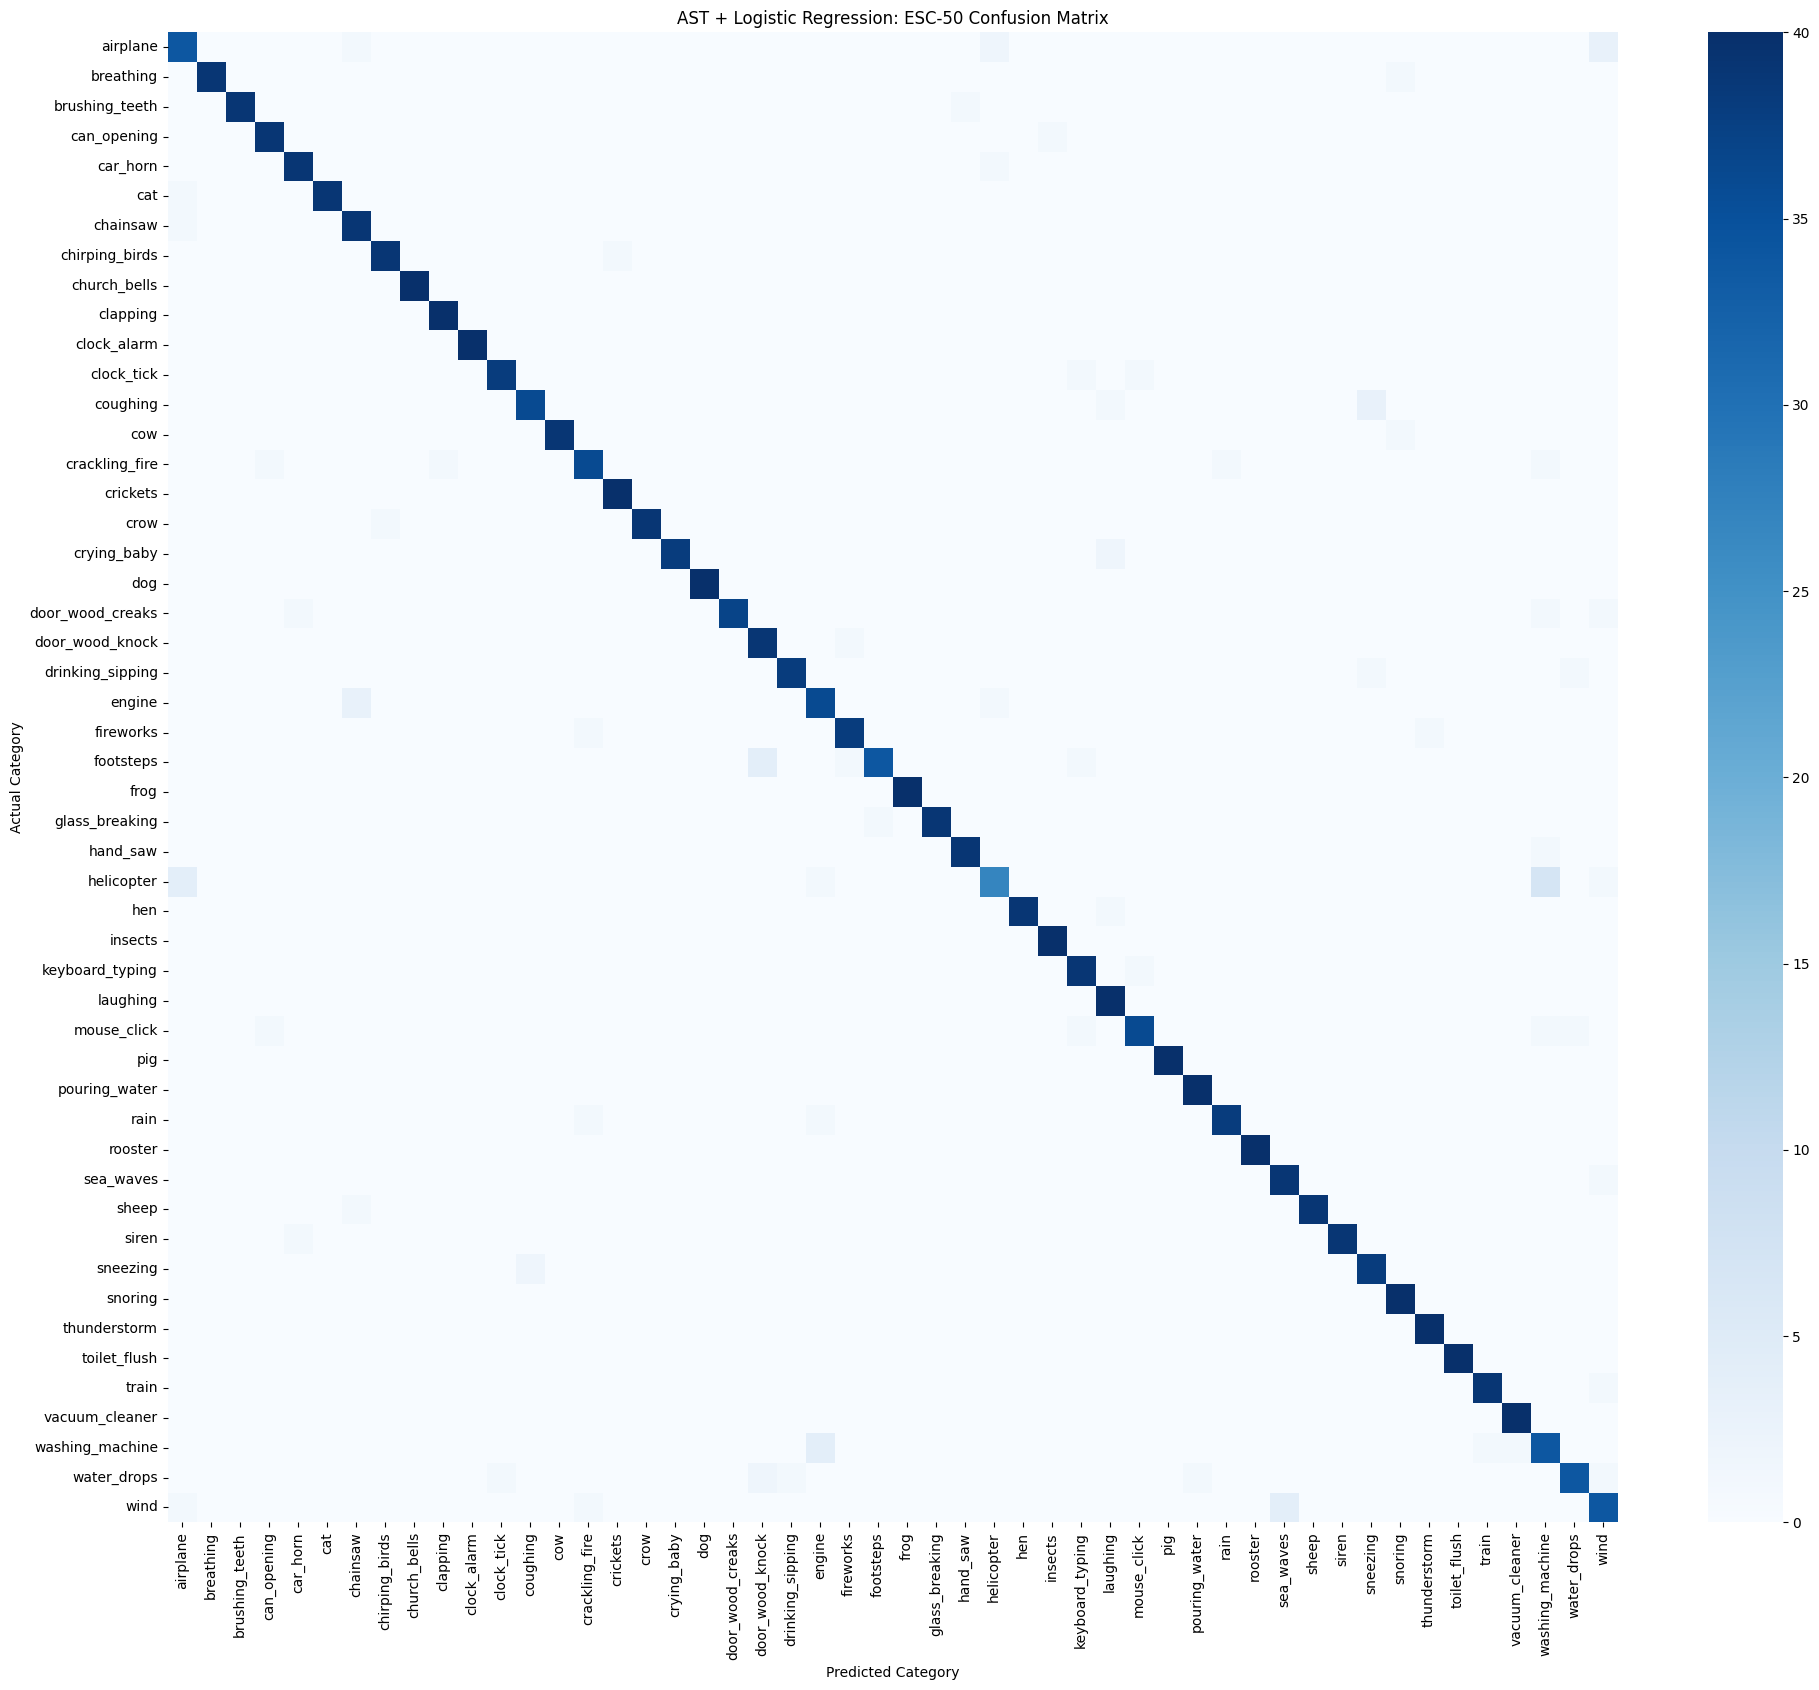

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(
    all_true_labels,
    all_predictions,
    labels=classes
)

plt.figure(figsize=(20, 17))

sns.heatmap(
    cm,
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes
)

plt.title("AST + Logistic Regression: ESC-50 Confusion Matrix")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

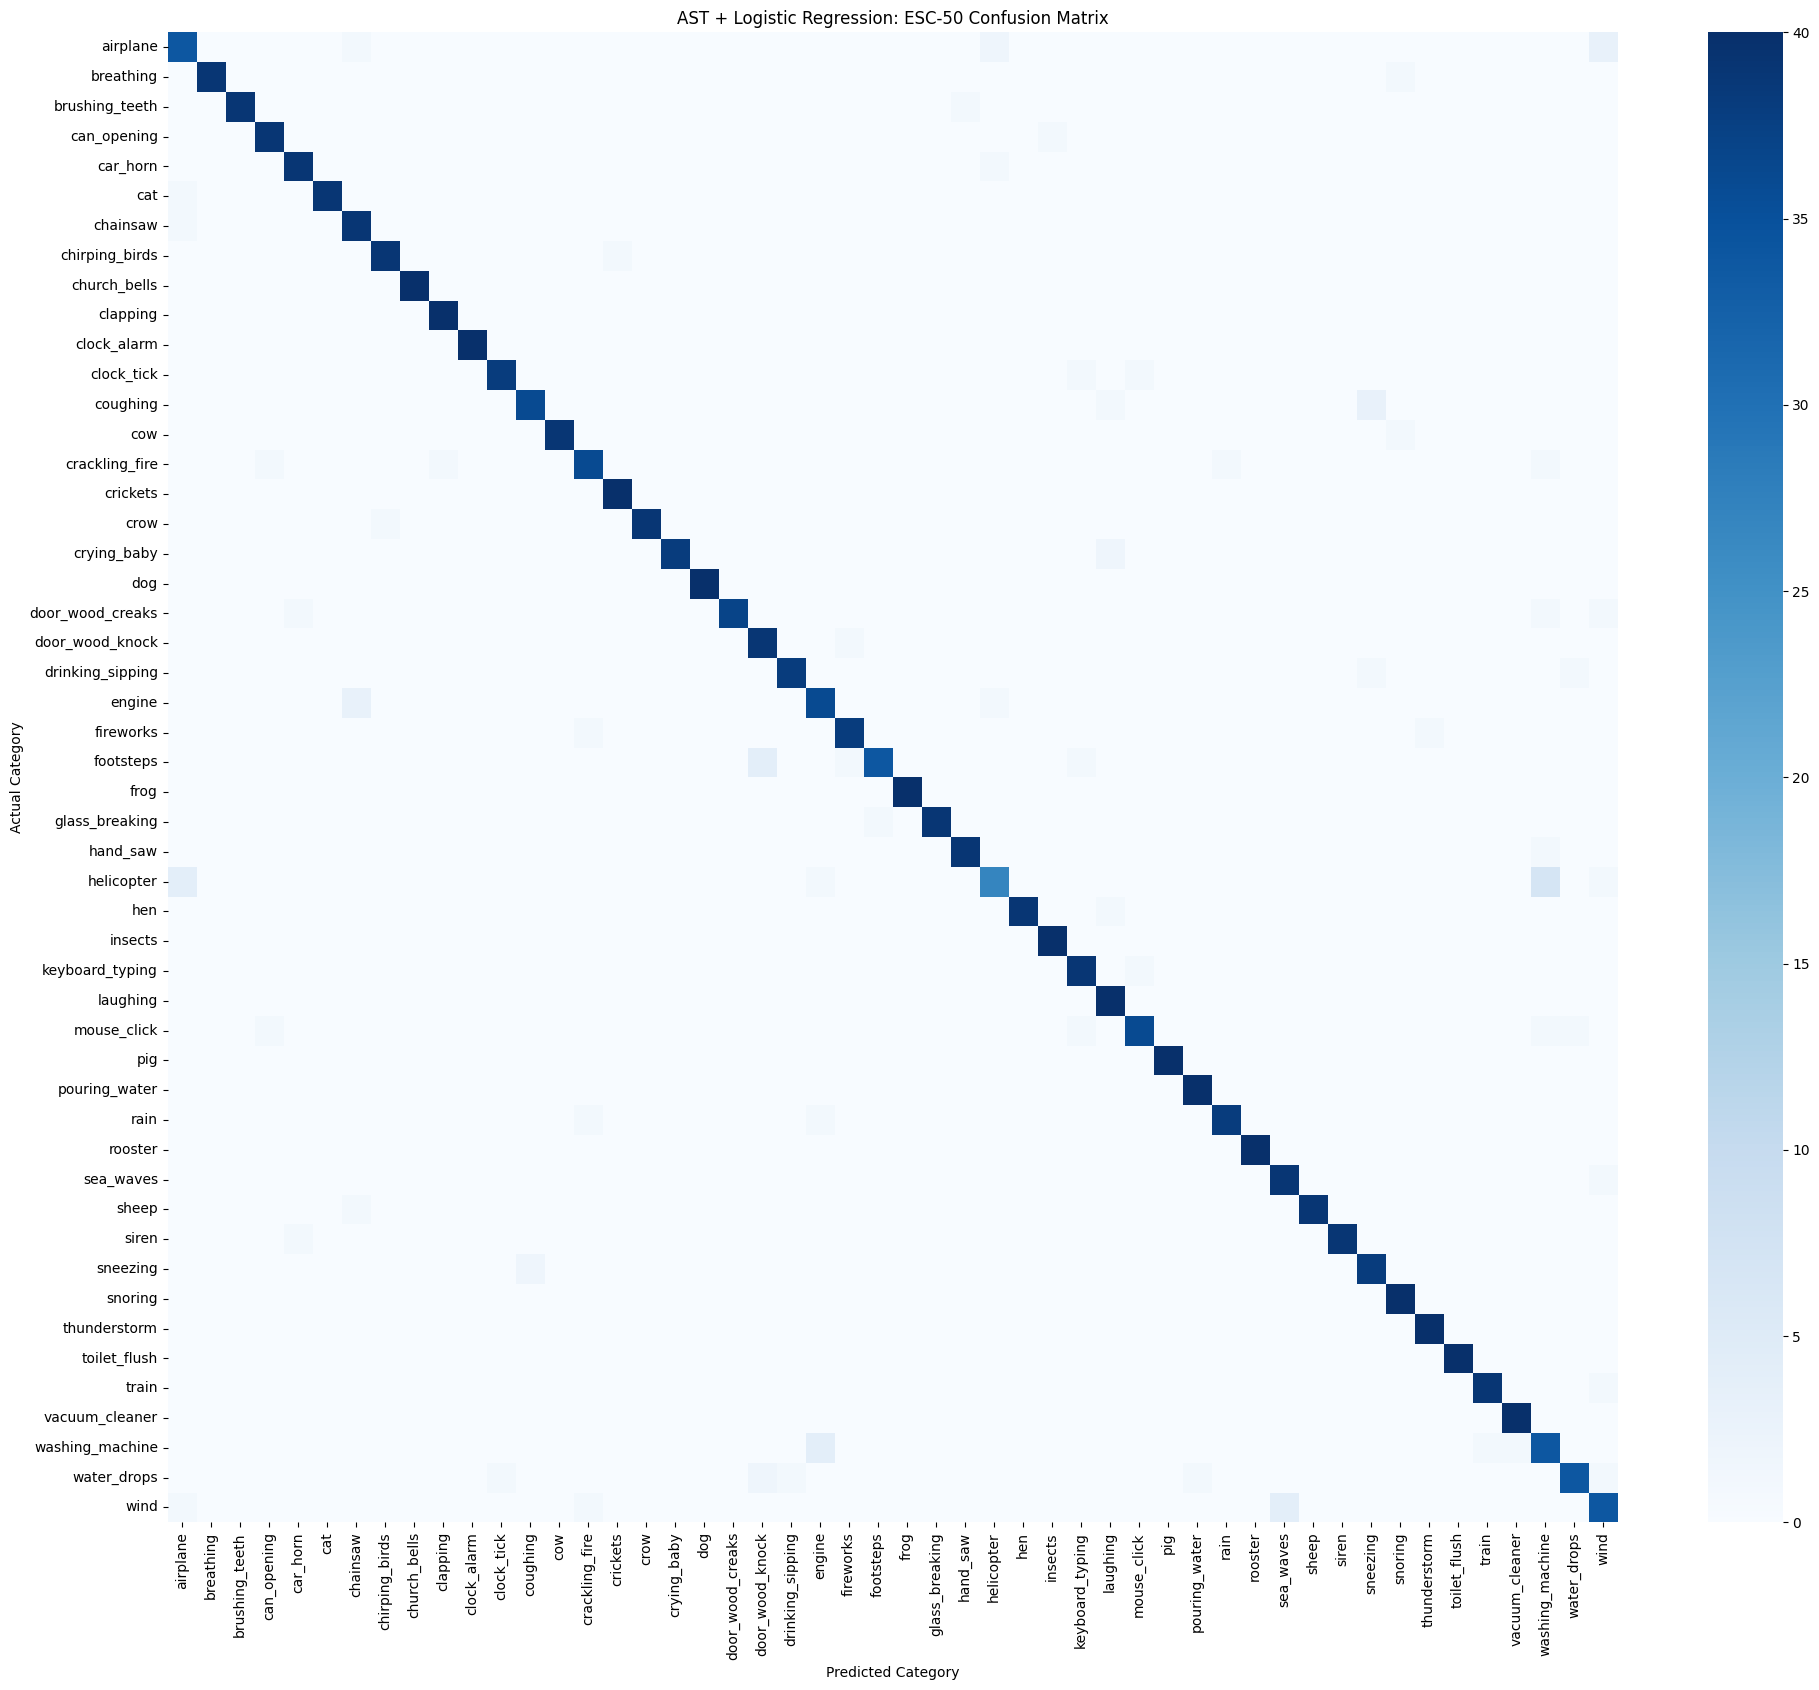

In [ ]:
plt.figure(figsize=(20, 17))

sns.heatmap(
    cm,
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes
)

plt.title("AST + Logistic Regression: ESC-50 Confusion Matrix")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()

plt.savefig(
    "/content/confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
def add_gaussian_noise(audio, snr_db, seed=42):

    rng = np.random.default_rng(seed)

    signal_power = np.mean(audio ** 2)

    if signal_power == 0:
        return audio.copy()

    noise = rng.normal(0, 1, len(audio))

    noise_power = np.mean(noise ** 2)

    required_noise_power = signal_power / (10 ** (snr_db / 10))

    noise = noise * np.sqrt(required_noise_power / noise_power)

    noisy_audio = audio + noise

    return noisy_audio.astype(np.float32)

In [ ]:
sample = metadata.iloc[0]

audio, _ = librosa.load(
    os.path.join(AUDIO_PATH, sample["filename"]),
    sr=16000,
    mono=True
)

noisy_audio = add_gaussian_noise(audio, snr_db=5)

print("Original audio shape:", audio.shape)
print("Noisy audio shape:", noisy_audio.shape)
print("Category:", sample["category"])

display(Audio(audio, rate=16000))
display(Audio(noisy_audio, rate=16000))

Original audio shape: (80000,)
Noisy audio shape: (80000,)
Category: dog


In [ ]:
def extract_embeddings_for_snr(snr_db, batch_size=16):
    embeddings = []

    for start in tqdm(range(0, len(metadata), batch_size)):
        batch_audio = []

        batch_rows = metadata.iloc[start:start + batch_size]

        for idx, row in batch_rows.iterrows():
            audio, _ = librosa.load(
                os.path.join(AUDIO_PATH, row["filename"]),
                sr=16000,
                mono=True
            )

            noisy_audio = add_gaussian_noise(
                audio,
                snr_db=snr_db,
                seed=42 + idx
            )

            batch_audio.append(noisy_audio)

        inputs = processor(
            batch_audio,
            sampling_rate=16000,
            return_tensors="pt"
        )

        inputs = {k: v.to(device) for k, v in inputs.items()}

        with torch.no_grad():
            outputs = ast_model(**inputs)

        batch_embeddings = outputs.last_hidden_state[:, 2:, :].mean(dim=1)
        embeddings.append(batch_embeddings.cpu().numpy())

    return np.concatenate(embeddings, axis=0)


snr_levels = [20, 10, 5, 0]

noisy_embeddings = {}

for snr in snr_levels:
    print(f"Extracting embeddings at {snr} dB SNR...")
    noisy_embeddings[snr] = extract_embeddings_for_snr(snr)

    print("Shape:", noisy_embeddings[snr].shape)

Extracting embeddings at 20 dB SNR...


  0%|          | 0/125 [00:00<?, ?it/s]

Shape: (2000, 768)
Extracting embeddings at 10 dB SNR...


  0%|          | 0/125 [00:00<?, ?it/s]

Shape: (2000, 768)
Extracting embeddings at 5 dB SNR...


  0%|          | 0/125 [00:00<?, ?it/s]

Shape: (2000, 768)
Extracting embeddings at 0 dB SNR...


  0%|          | 0/125 [00:00<?, ?it/s]

Shape: (2000, 768)


In [ ]:

from sklearn.metrics import accuracy_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

results = []

for fold in sorted(np.unique(folds)):
    train_mask = folds != fold
    test_mask = folds == fold

    clf = Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=2000,
            C=1.0,
            random_state=42
        ))
    ])

    clf.fit(X[train_mask], y[train_mask])

    clean_predictions = clf.predict(X[test_mask])

    results.append({
        "Fold": fold,
        "SNR": "Clean",
        "Accuracy": accuracy_score(y[test_mask], clean_predictions)
    })

    for snr in snr_levels:
        noisy_predictions = clf.predict(
            noisy_embeddings[snr][test_mask]
        )

        results.append({
            "Fold": fold,
            "SNR": f"{snr} dB",
            "Accuracy": accuracy_score(y[test_mask], noisy_predictions)
        })

robustness_df = pd.DataFrame(results)

display(robustness_df)


,Fold,SNR,Accuracy
0,1,Clean,0.9375
1,1,20 dB,0.9200
2,1,10 dB,0.8175
3,1,5 dB,0.6900
4,1,0 dB,0.4600
5,2,Clean,0.9725
6,2,20 dB,0.9300
7,2,10 dB,0.8200
8,2,5 dB,0.6925
9,2,0 dB,0.4500


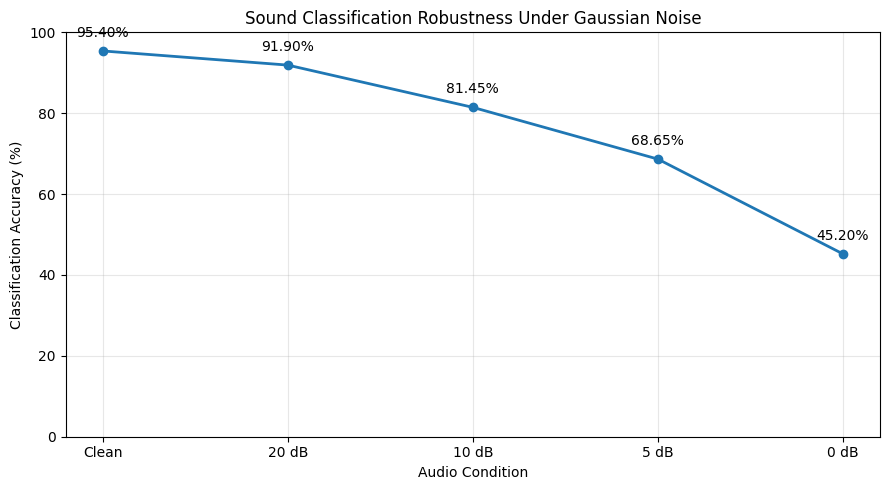

In [ ]:
import matplotlib.pyplot as plt

mean_accuracy = (
    robustness_df
    .groupby("SNR")["Accuracy"]
    .mean()
    .reindex(["Clean", "20 dB", "10 dB", "5 dB", "0 dB"])
)

plt.figure(figsize=(9, 5))

plt.plot(
    mean_accuracy.index,
    mean_accuracy.values * 100,
    marker="o",
    linewidth=2
)

plt.title("Sound Classification Robustness Under Gaussian Noise")
plt.xlabel("Audio Condition")
plt.ylabel("Classification Accuracy (%)")
plt.ylim(0, 100)
plt.grid(True, alpha=0.3)

for i, value in enumerate(mean_accuracy.values * 100):
    plt.annotate(
        f"{value:.2f}%",
        (i, value),
        textcoords="offset points",
        xytext=(0, 10),
        ha="center"
    )

plt.tight_layout()
plt.savefig("/content/robustness_plot.png", dpi=300)
plt.show()

In [ ]:
robustness_df.to_csv("/content/robustness_metrics.csv", index=False)

summary_df = (
    robustness_df
    .groupby("SNR")["Accuracy"]
    .agg(["mean", "std"])
    .reindex(["Clean", "20 dB", "10 dB", "5 dB", "0 dB"])
    .reset_index()
)

summary_df["mean"] = summary_df["mean"] * 100
summary_df["std"] = summary_df["std"] * 100

summary_df = summary_df.rename(columns={
    "mean": "Mean Accuracy (%)",
    "std": "Std Dev (%)"
})

summary_df.to_csv("/content/robustness_summary.csv", index=False)

display(summary_df)

,SNR,Mean Accuracy (%),Std Dev (%)
0,Clean,95.40,1.537043
1,20 dB,91.90,2.401822
2,10 dB,81.45,1.555233
3,5 dB,68.65,3.393928
4,0 dB,45.20,2.300815


In [ ]:
import os

files_to_check = [
    "/content/confusion_matrix.png",
    "/content/robustness_plot.png",
    "/content/robustness_metrics.csv",
    "/content/robustness_summary.csv"
]

for file in files_to_check:
    print(
        os.path.basename(file),
        "—",
        "Available" if os.path.exists(file) else "Not found"
    )

confusion_matrix.png — Available
robustness_plot.png — Available
robustness_metrics.csv — Available
robustness_summary.csv — Available


In [ ]:
import os
import shutil

RESULTS_PATH = "/content/SoundScope/results"

os.makedirs(RESULTS_PATH, exist_ok=True)

files_to_copy = [
    "/content/confusion_matrix.png",
    "/content/robustness_plot.png",
    "/content/robustness_metrics.csv",
    "/content/robustness_summary.csv"
]

for file in files_to_copy:
    shutil.copy2(
        file,
        os.path.join(RESULTS_PATH, os.path.basename(file))
    )

print("Results folder contents:")
print(os.listdir(RESULTS_PATH))

Results folder contents:
['confusion_matrix.png', 'robustness_metrics.csv', 'robustness_summary.csv', 'robustness_plot.png']


In [ ]:
from sklearn.metrics import classification_report

report = classification_report(
    all_true_labels,
    all_predictions,
    output_dict=True,
    zero_division=0
)

classification_df = pd.DataFrame(report).transpose()

classification_df.to_csv(
    os.path.join(RESULTS_PATH, "classification_report.csv")
)

display(classification_df.round(3))

,precision,recall,f1-score,support
airplane,0.829,0.850,0.840,40.000
breathing,1.000,0.975,0.987,40.000
brushing_teeth,1.000,0.975,0.987,40.000
can_opening,0.951,0.975,0.963,40.000
car_horn,0.951,0.975,0.963,40.000
cat,1.000,0.975,0.987,40.000
chainsaw,0.886,0.975,0.929,40.000
chirping_birds,0.975,0.975,0.975,40.000
church_bells,1.000,1.000,1.000,40.000
clapping,0.976,1.000,0.988,40.000


In [ ]:
import os

project_path = "/content/SoundScope"

folders = [
    "notebooks",
    "results",
    "src"
]

for folder in folders:
    os.makedirs(os.path.join(project_path, folder), exist_ok=True)

print("SoundScope project structure:")

for root, dirs, files in os.walk(project_path):
    level = root.replace(project_path, "").count(os.sep)
    indent = "    " * level
    print(f"{indent}{os.path.basename(root)}/")

    for file in files:
        print(f"{indent}    {file}")

SoundScope project structure:
SoundScope/
    results/
        confusion_matrix.png
        classification_report.csv
        robustness_metrics.csv
        robustness_summary.csv
        robustness_plot.png
    notebooks/
    src/


In [ ]:
from google.colab import drive